#### 다중분류 모델링 학습

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [16]:
# 다중 분류 모델의 손실함수 CrossEntropyLoss 는 목푯값을 인덱스(정수)로 사용
# y의 dtype 은 long(정수형)으로 생성해야 함
def make_Dataset(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.long)
    x_val_ts = torch.tensor(x_val, dtype= torch.float32)
    y_val_ts = torch.tensor(y_val, dtype= torch.long)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)

    return train_loader, x_val_ts, y_val_ts

In [4]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)  # dataloader가 사용하는 데이터셋의 샘플 수
    num_batches = len(dataloader)   # 318개의 인스턴스를 배치당 최대 32개씩 나눈값 = 10 개
    tr_loss = 0
    
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [ ]:
def evaluate(x_val_ts, y_val_ts, model, loss_fn, device):   # optimizer 필요 X
    model.eval()
    with torch.no_grad():
        x, y = x_val_ts.to(device), y_val_ts.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()

    return val_loss, pred

In [6]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train error', marker= '.')
    plt.plot(epochs, val_loss_list, label= 'val error', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

In [7]:
import requests
from io import BytesIO
import certifi

In [10]:
path = "https://bit.ly/irisdata_csv"
response = requests.get(path, verify= certifi.where(), timeout=15)
response.raise_for_status()
data = pd.read_csv(BytesIO(response.content))
data.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [17]:
target = 'Species'
x = data.drop(target, axis=1)
y = data.loc[:,target]

# 정수 인코딩
le = LabelEncoder()
y = le.fit_transform(y)

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.3, random_state= 20)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

train_loader, x_val_ts, y_val_ts = make_Dataset(x_train, x_val, y_train, y_val, 32)

In [19]:
class MLP(nn.Module):
    def __init__(self, n_feature, n_class):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(n_feature, 30),
                nn.ReLU(),
                nn.Linear(30, n_class)
            ).to(device)

    def forward(self, x):
        return self.linear(x)

In [20]:
LR = 1e-2
EPOCH = 100

n_feature = x.shape[1]
n_class = len(le.classes_)
model= MLP(n_feature, n_class)

optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

In [21]:
tr_loss_list, val_loss_list = [], []
for ep in range(EPOCH):
    tr_loss = train(train_loader, model, criterion, optimizer, device)
    val_loss, _ = evaluate(x_val_ts, y_val_ts, model, criterion, device)
    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)

    print(f'EP {ep+1}, TL {tr_loss}, VL {val_loss}')

EP 1, TL 1.108123540878296, VL 1.0843331813812256
EP 2, TL 1.0352745056152344, VL 1.0365132093429565
EP 3, TL 0.9867027997970581, VL 0.9832609295845032
EP 4, TL 0.8980587124824524, VL 0.9154161810874939
EP 5, TL 0.7993770837783813, VL 0.8452141880989075
EP 6, TL 0.7331801652908325, VL 0.7816436886787415
EP 7, TL 0.6557102799415588, VL 0.7117987871170044
EP 8, TL 0.5619574785232544, VL 0.6388936638832092
EP 9, TL 0.5475912690162659, VL 0.5789022445678711
EP 10, TL 0.47324132919311523, VL 0.5293598771095276
EP 11, TL 0.3899824023246765, VL 0.48719051480293274
EP 12, TL 0.39108195900917053, VL 0.4608994424343109
EP 13, TL 0.34996920824050903, VL 0.4348016083240509
EP 14, TL 0.34967532753944397, VL 0.41943037509918213
EP 15, TL 0.3341917395591736, VL 0.4094500243663788
EP 16, TL 0.33590465784072876, VL 0.3931886851787567
EP 17, TL 0.3199266195297241, VL 0.3660745322704315
EP 18, TL 0.2770293951034546, VL 0.35517483949661255
EP 19, TL 0.27233952283859253, VL 0.34313949942588806
EP 20, TL 0.

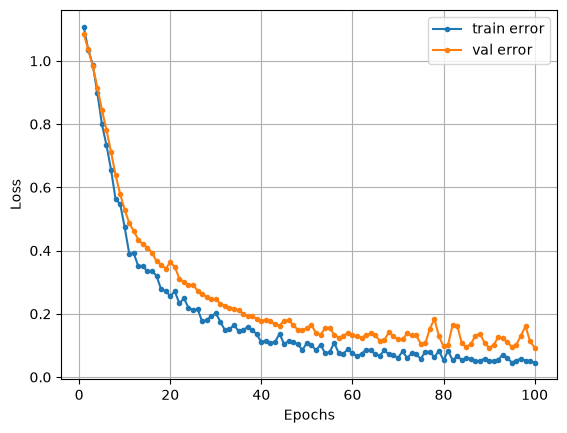

In [22]:
learning_curve(tr_loss_list, val_loss_list)

In [25]:
# classification_report
_, pred = evaluate(x_val_ts, y_val_ts, model, criterion, device)
pred = torch.softmax(pred, dim=1)
pred = np.argmax(pred.numpy(), axis=1)
true = y_val_ts.numpy()
report = classification_report(true, pred, target_names= le.classes_)
print(report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.95      1.00      0.97        18
   virginica       1.00      0.93      0.96        14

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



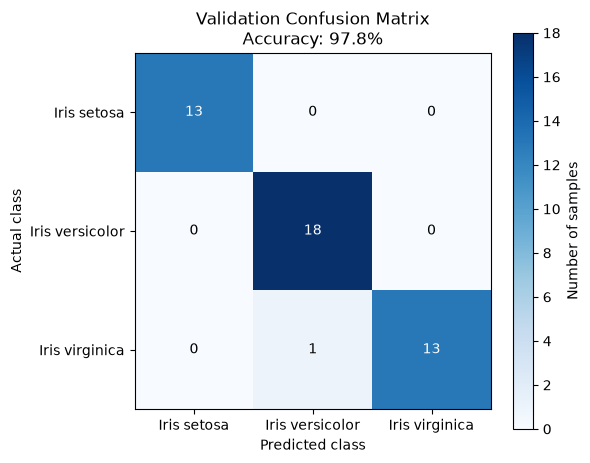

In [26]:
# confusion matrix visualization
class_indices = np.arange(n_class)  # [0, 1, 2]
class_names = [
    f'Iris {original_class}' for original_class in le.classes_
]

cm = confusion_matrix(true, pred, labels= class_indices)
accuracy = accuracy_score(true, pred)

fig, ax = plt.subplots(figsize=(6,5))

im = ax.imshow(cm, cmap= 'Blues')
fig.colorbar(im, ax=ax, label='Number of samples')

ax.set_xticks(class_indices)
ax.set_yticks(class_indices)
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_title(f'Validation Confusion Matrix\nAccuracy: {accuracy:.1%}')

# 각 칸에 샘플 수 표시
for row in range(n_class):
    for col in range(n_class):
        ax.text(
            col, row, str(cm[row, col]),
            ha='center',
            va='center',
            color='white' if cm[row, col] > cm.max() / 2 else 'black'
        )

plt.tight_layout()
plt.show()